# Data Preparation, Calibration and Difficulty Stratification Pipeline
This notebook implements the complete data preparation pipeline supporting Section 3.3 (Generation Rounds and Audit), Section 3.4 (Input-Threshold Recalibration), and Section 3.5 (Quantile-Based Difficulty Stratification).

### Pipeline Outline
1. Model Audit: Evaluate pretrained unitary/unbiased-toxic-roberta classifier ROC-AUC on the full 9,631 corpus.
2. Stratified Split: Partition 9,631 samples into Train (55%), Validation (15%), and Test (30%) splits in data/01_full_splits.
3. Threshold Calibration: Load classifier, evaluate validation set ROC-AUC, and scan thresholds on Validation split to determine optimal Youden's J cutoff (tau = 0.0100).
4. Filtering: Extract active training corpus (s(x) >= 0.0100) into data/02_filtered_splits.
5. Difficulty Stratification: Compute quantile cutoffs on filtered Train set and map Easy, Medium, and Hard bands into data/03_stratified_benchmark.


## 1. Pretrained Classifier Audit and ROC-AUC on Full Corpus (n = 9,631)
Aligns with Section 3.3 (Generation Rounds and Audit):
The pretrained classifier unitary/unbiased-toxic-roberta is evaluated against prompted toxicity labels on the full 9,631 corpus.


In [2]:
# =============================================================================
# 1. EVALUATE CLASSIFIER ROC-AUC ON FULL CORPUS (n = 9,631) VIA LIVE INFERENCE
# =============================================================================
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score, average_precision_score

# 1. Load full dataset
data_path = Path("../01_data_generation/data/final_corpus_9631.csv")
if not data_path.exists():
    data_path = Path("01_data_generation/data/final_corpus_9631.csv")
if not data_path.exists():
    data_path = Path("01_data_generation/data/final_corpus_9631.csv")

df = pd.read_csv(data_path)
df_corpus = df  # alias used by downstream split logic
print(f"Loaded full dataset: {data_path.as_posix()} ({len(df):,} samples)")

y_true = df["label"].astype(str).str.strip().str.lower().eq("toxic").astype(int).to_numpy()
texts = df["text"].fillna("").astype(str).tolist()

# 2. Load pretrained unbiased classifier
MODEL_NAME = "unitary/unbiased-toxic-roberta"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Loading {MODEL_NAME} on {device}...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME).to(device)
model.eval()

id2label = {int(k): str(v).lower() for k, v in model.config.id2label.items()}
toxicity_idx = next((idx for idx, name in id2label.items() if name == "toxicity"), 0)

# 3. Chay suy luan co thanh tien trinh tqdm (y het file cu)
batch_size = 32
new_scores = []

print(f"Scoring {len(texts):,} samples via model inference...")
for i in tqdm(range(0, len(texts), batch_size), desc="Scoring"):
    batch = texts[i:i + batch_size]
    inputs = tokenizer(batch, padding=True, truncation=True, max_length=512, return_tensors="pt").to(device)
    with torch.no_grad():
        logits = model(**inputs).logits
        probs = torch.sigmoid(logits)[:, toxicity_idx].cpu().numpy()
        new_scores.extend(probs.tolist())

y_scores = np.array(new_scores)

# 4. Compute ROC-AUC and PR-AUC
overall_roc_auc = roc_auc_score(y_true, y_scores)
overall_pr_auc = average_precision_score(y_true, y_scores)

print("=" * 70)
print("FULL CORPUS CLASSIFIER AUDIT RESULT (unitary/unbiased-toxic-roberta):")
print(f"  Full Corpus Size : {len(df):,} samples")
print(f"  Toxic samples    : {int(y_true.sum()):,} ({y_true.mean()*100:.2f}%)")
print(f"  Non-toxic samples: {int((1 - y_true).sum()):,} ({(1 - y_true).mean()*100:.2f}%)")
print(f"  Full ROC-AUC     : {overall_roc_auc:.4f}")
print(f"  Full PR-AUC      : {overall_pr_auc:.4f}")
print("=" * 70)


Loaded full dataset: 01_data_generation/data/final_corpus_9631.csv (9,631 samples)
Loading unitary/unbiased-toxic-roberta on cpu...


Loading weights: 100%|██████████| 201/201 [00:01<00:00, 160.25it/s]

RobertaForSequenceClassification LOAD REPORT from: unitary/unbiased-toxic-roberta
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.

Scoring 9,631 samples via model inference...


FULL CORPUS CLASSIFIER AUDIT RESULT (unitary/unbiased-toxic-roberta):
  Full Corpus Size : 9,631 samples
  Toxic samples    : 7,593 (78.84%)
  Non-toxic samples: 2,038 (21.16%)
  Full ROC-AUC     : 0.6836
  Full PR-AUC      : 0.8913


## 2. Stratified Train / Validation / Test Split (55% / 15% / 30%)
Stratified partitioning assigns 5,297 samples (55%) to the training split, 1,444 samples (15%) to the validation split, and 2,890 samples (30%) to the test split.
Stratification is performed jointly over label and subtype with fixed random_state = 42.


In [2]:
from pathlib import Path
from sklearn.model_selection import StratifiedShuffleSplit

# Check existing split directory
df_corpus = df  # from Cell 1 (full corpus with scores)

split_dir = Path("data/01_full_splits")

if (split_dir / "train.csv").exists():
    train_df = pd.read_csv(split_dir / "train.csv")
    val_df = pd.read_csv(split_dir / "val.csv")
    test_df = pd.read_csv(split_dir / "test.csv")
    print(f"Loaded existing stratified splits from '{split_dir.as_posix()}':")
else:
    # Perform stratified split (55% train, 15% val, 30% test)
    df_corpus['strat_key'] = df_corpus['label'] + '__' + df_corpus['subtype']
    
    # First split: 70% train+val, 30% test
    sss_test = StratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
    train_val_idx, test_idx = next(sss_test.split(df_corpus, df_corpus['strat_key']))
    df_train_val = df_corpus.iloc[train_val_idx].reset_index(drop=True)
    test_df = df_corpus.iloc[test_idx].reset_index(drop=True)
    
    # Second split: from 70%, split into 55% train (55/70 = 0.785714) and 15% val
    val_ratio_in_train_val = 0.15 / 0.70
    sss_val = StratifiedShuffleSplit(n_splits=1, test_size=val_ratio_in_train_val, random_state=42)
    train_idx, val_idx = next(sss_val.split(df_train_val, df_train_val['strat_key']))
    train_df = df_train_val.iloc[train_idx].reset_index(drop=True)
    val_df = df_train_val.iloc[val_idx].reset_index(drop=True)
    
    for d in [train_df, val_df, test_df]:
        if 'strat_key' in d.columns:
            d.drop(columns=['strat_key'], inplace=True)
    print("Computed stratified split 55% / 15% / 30%:")

print(f"  Train set : {len(train_df):5,} samples ({len(train_df)/(len(train_df) + len(val_df) + len(test_df))*100:5.2f}%)")
print(f"  Val set   : {len(val_df):5,} samples ({len(val_df)/(len(train_df) + len(val_df) + len(test_df))*100:5.2f}%)")
print(f"  Test set  : {len(test_df):5,} samples ({len(test_df)/(len(train_df) + len(val_df) + len(test_df))*100:5.2f}%)")
print(f"  Total     : {len(train_df) + len(val_df) + len(test_df):5,} samples (100.00%)")


Loaded existing stratified splits from 'data/01_full_splits':
  Train set : 5,297 samples (55.00%)
  Val set   : 1,444 samples (14.99%)
  Test set  : 2,890 samples (30.01%)
  Total     : 9,631 samples (100.00%)


### Export: Save data/01_full_splits
Set EXPORT_SPLIT = True to export split files to data/01_full_splits. Default is False to preserve existing data files.


In [3]:
EXPORT_SPLIT = False

if EXPORT_SPLIT:
    out_dir = Path("data/01_full_splits")
    out_dir.mkdir(parents=True, exist_ok=True)
    
    train_df.to_csv(out_dir / "train.csv", index=False)
    val_df.to_csv(out_dir / "val.csv", index=False)
    test_df.to_csv(out_dir / "test.csv", index=False)
    print(f"Exported split files to '{out_dir}/'")
else:
    print("Export skipped (EXPORT_SPLIT = False). Set to True to re-export.")


Export skipped (EXPORT_SPLIT = False). Set to True to re-export.


## 3. Threshold Scanning on Validation Set (val.csv)
Aligns with Section 3.4 (Input-Threshold Recalibration):
The unbiased classifier is loaded to evaluate ROC-AUC on the validation split. Thresholds tau in [0.0001, 0.50] are scanned to find the optimal cutoff maximizing Youden's J statistic (J = TPR - FPR = Sensitivity + Specificity - 1).


In [4]:
# =============================================================================
# 2. EVALUATE CLASSIFIER ROC-AUC ON VALIDATION SPLIT (n = 1,444)
# =============================================================================
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import roc_auc_score, average_precision_score

# 1. Load validation split
val_path = Path("data/01_full_splits/val.csv")
if not val_path.exists():
    val_path = Path("02_data_preparation/data/01_full_splits/val.csv")

val_df = pd.read_csv(val_path)
print(f"Loaded validation split: {val_path.as_posix()} ({len(val_df):,} samples)")

y_val = val_df["label"].astype(str).str.strip().str.lower().eq("toxic").astype(int).to_numpy()
texts_val = val_df["text"].fillna("").astype(str).tolist()

# 2. Load pretrained unbiased classifier
MODEL_NAME = "unitary/unbiased-toxic-roberta"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Loading {MODEL_NAME} on {device}...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME).to(device)
model.eval()

id2label = {int(k): str(v).lower() for k, v in model.config.id2label.items()}
toxicity_idx = next((idx for idx, name in id2label.items() if name == "toxicity"), 0)

# 3. Model inference on validation split
scores_val = []
BATCH_SIZE = 32
MAX_LENGTH = 256

print(f"Scoring validation split ({len(texts_val):,} samples) via model inference...")
with torch.no_grad():
    for start in range(0, len(texts_val), BATCH_SIZE):
        batch_texts = texts_val[start:start + BATCH_SIZE]
        batch = tokenizer(batch_texts, padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(device)
        logits = model(**batch).logits
        probs = torch.sigmoid(logits)[:, toxicity_idx]
        scores_val.extend(probs.detach().cpu().numpy().tolist())

scores_val = np.asarray(scores_val, dtype=float)

# 4. Compute Validation ROC-AUC and PR-AUC
val_roc_auc = roc_auc_score(y_val, scores_val)
val_pr_auc = average_precision_score(y_val, scores_val)

print("=" * 70)
print("VALIDATION SET CLASSIFIER AUDIT (unitary/unbiased-toxic-roberta):")
print(f"  Validation samples : {len(val_df):,}")
print(f"  Toxic samples      : {int(y_val.sum()):,} ({y_val.mean()*100:.2f}%)")
print(f"  Non-toxic samples  : {int((1 - y_val).sum()):,} ({(1 - y_val).mean()*100:.2f}%)")
print(f"  Validation ROC-AUC : {val_roc_auc:.4f}")
print(f"  Validation PR-AUC  : {val_pr_auc:.4f}")
print("=" * 70)


Loaded validation split: data/01_full_splits/val.csv (1,444 samples)
Loading unitary/unbiased-toxic-roberta on cpu...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: unitary/unbiased-toxic-roberta
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Scoring validation split (1,444 samples) via model inference...
VALIDATION SET CLASSIFIER AUDIT (unitary/unbiased-toxic-roberta):
  Validation samples : 1,444
  Toxic samples      : 1,138 (78.81%)
  Non-toxic samples  : 306 (21.19%)
  Validation ROC-AUC : 0.6981
  Validation PR-AUC  : 0.8959


Loaded validation split: data/01_full_splits/val.csv (1,444 samples)
Loading unitary/unbiased-toxic-roberta on cpu...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: unitary/unbiased-toxic-roberta
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Scoring validation split via model inference...
VALIDATION THRESHOLD SCANNING RESULT:
  Optimal Threshold by Youden's J : tau = 0.0060
  Max Youden J Statistic          : 0.2701
  Toxic Recall at tau = 0.0100    : 52.20%
  Toxic Precision at tau = 0.0100 : 88.00%


Threshold,Pred Non-Toxic,Pred Toxic,Toxic Recall,Toxic Precision,Youden J
0.0001,0,1444,1.0000,0.7881,0.0000
0.001,599,845,0.6371,0.8580,0.2449
0.002,668,776,0.5888,0.8634,0.2423
0.003,703,741,0.5668,0.8704,0.2531
0.004,718,726,0.5562,0.8719,0.2523
0.005,734,710,0.5483,0.8789,0.2673
0.006,745,699,0.5413,0.8813,0.2701
0.007,751,693,0.5360,0.8802,0.2648
0.008,757,687,0.5316,0.8806,0.2637
0.009,763,681,0.5272,0.8811,0.2625


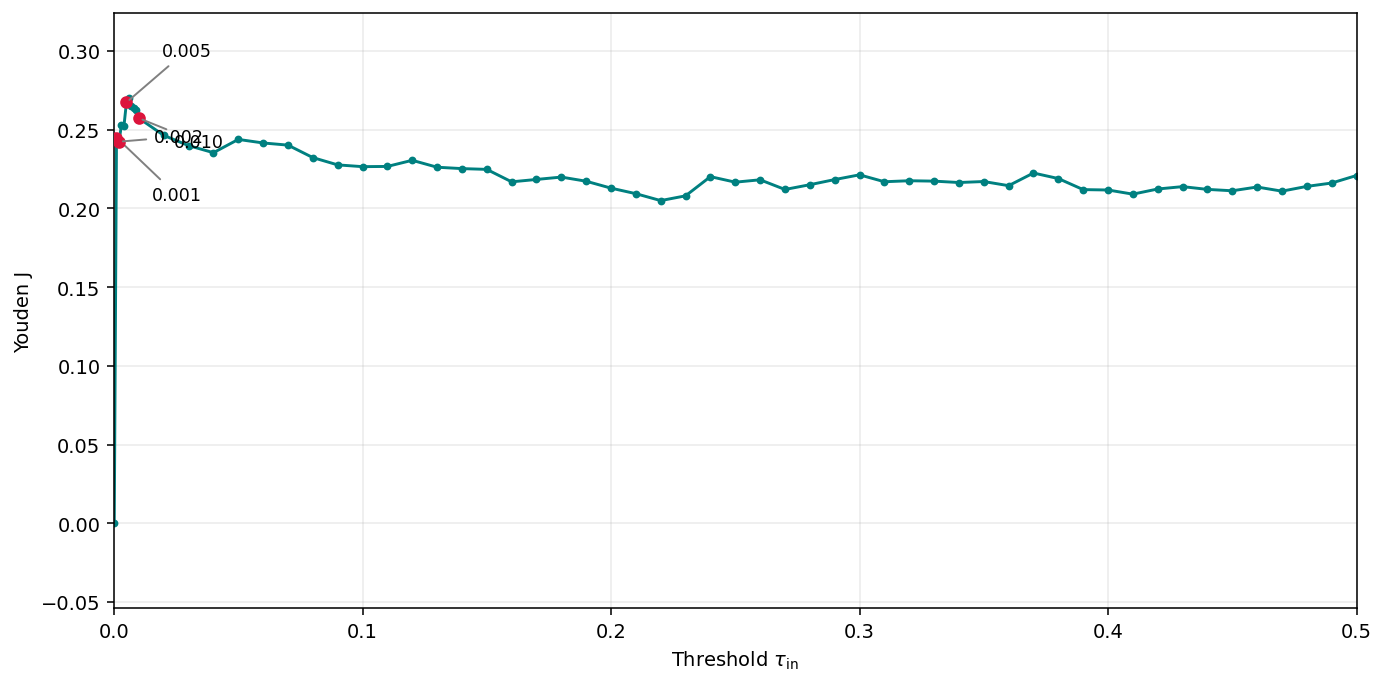

In [5]:
# =============================================================================
# 3. THRESHOLD SCANNING ON VALIDATION SPLIT AND YOUDEN'S J CURVE
# =============================================================================
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display
from transformers import AutoModelForSequenceClassification, AutoTokenizer

# 1. Load validation dataset
val_path = Path("data/01_full_splits/val.csv")
if not val_path.exists():
  val_path = Path(
      "02_data_preparation/data/01_full_splits/val.csv"
  )

val_df = pd.read_csv(val_path)
print(f"Loaded validation split: {val_path.as_posix()} ({len(val_df):,} samples)")

y_val = (
    val_df["label"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("toxic")
    .astype(int)
    .to_numpy()
)
texts_val = val_df["text"].fillna("").astype(str).tolist()

# 2. Live model inference with unitary/unbiased-toxic-roberta
MODEL_NAME = "unitary/unbiased-toxic-roberta"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Loading {MODEL_NAME} on {device}...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME).to(device)
model.eval()

id2label = {int(k): str(v).lower() for k, v in model.config.id2label.items()}
toxicity_idx = next(
    (idx for idx, name in id2label.items() if name == "toxicity"), 0
)

scores_val = []
BATCH_SIZE = 32
MAX_LENGTH = 256

print("Scoring validation split via model inference...")
with torch.no_grad():
  for start in range(0, len(texts_val), BATCH_SIZE):
    batch_texts = texts_val[start : start + BATCH_SIZE]
    batch = tokenizer(
        batch_texts,
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt",
    ).to(device)
    logits = model(**batch).logits
    probs = torch.sigmoid(logits)[:, toxicity_idx]
    scores_val.extend(probs.detach().cpu().numpy().tolist())

scores_val = np.asarray(scores_val, dtype=float)

# 3. Threshold scanning grid (60 cutoffs)
thresholds = np.array(
    [0.0001]
    + [i / 1000 for i in range(1, 11)]
    + [i / 100 for i in range(2, 51)]
)
rows = []

for threshold in thresholds:
  y_pred = scores_val >= threshold
  tp = int(((y_val == 1) & y_pred).sum())
  fp = int(((y_val == 0) & y_pred).sum())
  tn = int(((y_val == 0) & ~y_pred).sum())
  fn = int(((y_val == 1) & ~y_pred).sum())

  recall = tp / (tp + fn) if tp + fn else 0.0
  precision = tp / (tp + fp) if tp + fp else 0.0
  fpr = fp / (fp + tn) if fp + tn else 0.0
  rows.append({
      "Threshold": threshold,
      "Pred Non-Toxic": tn + fn,
      "Pred Toxic": tp + fp,
      "Toxic Recall": recall,
      "Toxic Precision": precision,
      "Youden J": recall - fpr,
  })

df_res = pd.DataFrame(rows)

# Optimal Youden J summary
best_idx = df_res["Youden J"].idxmax()
best_tau = df_res.loc[best_idx, "Threshold"]
best_j = df_res.loc[best_idx, "Youden J"]

print("=" * 70)
print("VALIDATION THRESHOLD SCANNING RESULT:")
print(f"  Optimal Threshold by Youden's J : tau = {best_tau:.4f}")
print(f"  Max Youden J Statistic          : {best_j:.4f}")
tau_01_row = df_res.loc[np.isclose(df_res["Threshold"], 0.01)].iloc[0]
print(
    f"  Toxic Recall at tau = 0.0100    : {tau_01_row['Toxic Recall']*100:.2f}%"
)
print(
    "  Toxic Precision at tau = 0.0100 :"
    f" {tau_01_row['Toxic Precision']*100:.2f}%"
)
print("=" * 70)

# Display HTML table
display(
    HTML(
        df_res.to_html(
            index=False,
            formatters={
                "Threshold": lambda v: f"{v:.4f}".rstrip("0").rstrip("."),
                "Toxic Recall": "{:.4f}".format,
                "Toxic Precision": "{:.4f}".format,
                "Youden J": "{:.4f}".format,
            },
        )
    )
)

# Plot Youden's J curve
fig, ax = plt.subplots(figsize=(10, 5), dpi=140)
ax.plot(
    df_res["Threshold"],
    df_res["Youden J"],
    marker="o",
    markersize=3,
    linewidth=1.5,
    color="teal",
    label="Youden J",
)
for threshold, offset in [
    (0.001, (18, -32)),
    (0.002, (18, 0)),
    (0.005, (18, 24)),
    (0.010, (18, -15)),
]:
  matching = df_res.loc[np.isclose(df_res["Threshold"], threshold)]
  if not matching.empty:
    row = matching.iloc[0]
    ax.scatter(threshold, row["Youden J"], color="crimson", s=30, zorder=3)
    ax.annotate(
        f"{threshold:.3f}",
        (threshold, row["Youden J"]),
        xytext=offset,
        textcoords="offset points",
        arrowprops={"arrowstyle": "-", "color": "gray"},
        fontsize=9,
    )
ax.set_xlabel(r"Threshold $\tau_{\mathrm{in}}$")
ax.set_ylabel("Youden J")
ax.set_xlim(0, 0.5)
ax.margins(y=0.2)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


## 4. Filter Subsets with Calibrated Threshold tau = 0.0100 (data/02_filtered_splits)
Filters out low-score samples (s(x) < 0.0100) across Train, Validation, and Test sets.


In [6]:
RECALIBRATED_THRESHOLD = 0.0100

train_filtered = train_df[train_df['score'] >= RECALIBRATED_THRESHOLD].copy().reset_index(drop=True)
val_filtered = val_df[val_df['score'] >= RECALIBRATED_THRESHOLD].copy().reset_index(drop=True)
test_filtered = test_df[test_df['score'] >= RECALIBRATED_THRESHOLD].copy().reset_index(drop=True)
combine_filtered = pd.concat([train_filtered, val_filtered, test_filtered], ignore_index=True)

print("=" * 80)
print(f"FILTERED DATASET COUNTS (s(x) >= {RECALIBRATED_THRESHOLD:.4f}):")
print(f"  Filtered Train : {len(train_filtered):5,} samples (Removed {len(train_df) - len(train_filtered):,} low-score samples)")
print(f"  Filtered Val   : {len(val_filtered):5,} samples (Removed {len(val_df) - len(val_filtered):,} low-score samples)")
print(f"  Filtered Test  : {len(test_filtered):5,} samples (Removed {len(test_df) - len(test_filtered):,} low-score samples)")
print(f"  Filtered Total : {len(combine_filtered):5,} samples (Retained active training corpus)")
print(f"  Minimum score in filtered corpus: {combine_filtered['score'].min():.6f}")
print("=" * 80)


FILTERED DATASET COUNTS (s(x) >= 0.0100):
  Filtered Train : 2,424 samples (Removed 2,873 low-score samples)
  Filtered Val   :   672 samples (Removed 772 low-score samples)
  Filtered Test  : 1,312 samples (Removed 1,578 low-score samples)
  Filtered Total : 4,408 samples (Retained active training corpus)
  Minimum score in filtered corpus: 0.010118


### Export: Save data/02_filtered_splits
Set EXPORT_FILTERED = True to export filtered files to data/02_filtered_splits. Default is False to preserve existing data files.


In [7]:
EXPORT_FILTERED = False

if EXPORT_FILTERED:
    out_dir_f = Path("data/02_filtered_splits")
    out_dir_f.mkdir(parents=True, exist_ok=True)
    
    train_filtered.to_csv(out_dir_f / "train.csv", index=False)
    val_filtered.to_csv(out_dir_f / "val.csv", index=False)
    test_filtered.to_csv(out_dir_f / "test.csv", index=False)
    combine_filtered.to_csv(out_dir_f / "combine_data_filtered.csv", index=False)
    print(f"Exported filtered subset files to '{out_dir_f}/'")
else:
    print("Export skipped (EXPORT_FILTERED = False). Set to True to re-export.")


Export skipped (EXPORT_FILTERED = False). Set to True to re-export.


## 5. Quantile-Based Difficulty Stratification (data/03_stratified_benchmark)
Aligns with Section 3.5:
Difficulty bands target proportions of 47.4% Easy, 31.1% Medium, and 21.5% Hard.
Cutoff 1 corresponds to the 47.4% empirical rank on sorted filtered Train (0.4758).
Cutoff 2 corresponds to the 78.5% cumulative rank on sorted filtered Train (0.9745).


In [8]:
# Compute dynamic quantile cutoffs on sorted filtered Train set
train_sorted = train_filtered.sort_values('score').reset_index(drop=True)
N_train = len(train_sorted)

n_easy_target = int(round(N_train * 0.474))  # 1,149 samples
n_med_target = int(round(N_train * 0.311))   # 754 samples

# Cutoffs computed as midpoints at target rank boundaries without hardcoding
cutoff_1 = (train_sorted.loc[n_easy_target - 1, 'score'] + train_sorted.loc[n_easy_target, 'score']) / 2.0
cutoff_2 = (train_sorted.loc[n_easy_target + n_med_target - 1, 'score'] + train_sorted.loc[n_easy_target + n_med_target, 'score']) / 2.0

print("=" * 80)
print(f"QUANTILE DIFFICULTY CUTOFFS (Computed from N_train = {N_train:,}):")
print(f"  Easy   range : [0.0100, {cutoff_1:.4f})  (Target: 47.4% -> {n_easy_target:,} samples)")
print(f"  Medium range : [{cutoff_1:.4f}, {cutoff_2:.4f})  (Target: 31.1% -> {n_med_target:,} samples)")
print(f"  Hard   range : [{cutoff_2:.4f}, 1.0000]  (Target: 21.5% -> {N_train - n_easy_target - n_med_target:,} samples)")
print("=" * 80)

def assign_difficulty_band(s):
    if s < cutoff_1:
        return 'easy'
    elif s < cutoff_2:
        return 'medium'
    else:
        return 'hard'

train_final = train_filtered.copy()
val_final = val_filtered.copy()
test_final = test_filtered.copy()

for d in [train_final, val_final, test_final]:
    d['band'] = d['score'].apply(assign_difficulty_band)

print("Applied difficulty stratification to Train, Val, and Test splits successfully!")


QUANTILE DIFFICULTY CUTOFFS (Computed from N_train = 2,424):
  Easy   range : [0.0100, 0.4758)  (Target: 47.4% -> 1,149 samples)
  Medium range : [0.4758, 0.9745)  (Target: 31.1% -> 754 samples)
  Hard   range : [0.9745, 1.0000]  (Target: 21.5% -> 521 samples)
Applied difficulty stratification to Train, Val, and Test splits successfully!


In [9]:
from pathlib import Path
import pandas as pd
from IPython.display import HTML, display
# 1. Load splits from data/03_stratified_benchmark (or use in-memory DataFrames if available)
benchmark_dir = Path("data/03_stratified_benchmark")
if not benchmark_dir.exists():
  benchmark_dir = Path(
      "02_data_preparation/data/03_stratified_benchmark"
  )
try:
  df_tr = train_final
  df_va = val_final
  df_te = test_final
except NameError:
  df_tr = pd.read_csv(benchmark_dir / "train.csv")
  df_va = pd.read_csv(benchmark_dir / "val.csv")
  df_te = pd.read_csv(benchmark_dir / "test.csv")
# 2. Extract cutoffs if present in memory, else use standard benchmark boundaries
try:
  c1, c2 = cutoff_1, cutoff_2
except NameError:
  c1, c2 = 0.4757, 0.9745
band_specs = [
    ("Easy", f"[0.0100, {c1:.4f})", "47.4%", "easy"),
    ("Medium", f"[{c1:.4f}, {c2:.4f})", "31.1%", "medium"),
    ("Hard", f"[{c2:.4f}, 1.0000]", "21.5%", "hard"),
]
n_tr, n_va, n_te = len(df_tr), len(df_va), len(df_te)
table_rows = []
# 3. Compute counts and percentages per split
for label, s_range, target, key in band_specs:
  cnt_tr = (df_tr["band"].astype(str).str.lower() == key).sum()
  cnt_va = (df_va["band"].astype(str).str.lower() == key).sum()
  cnt_te = (df_te["band"].astype(str).str.lower() == key).sum()
  table_rows.append({
      "Band": label,
      "Score range": s_range,
      "Target": target,
      "Train": f"{cnt_tr:,} ({cnt_tr / n_tr * 100:.1f}%)",
      "Val.": f"{cnt_va:,} ({cnt_va / n_va * 100:.1f}%)",
      "Test": f"{cnt_te:,} ({cnt_te / n_te * 100:.1f}%)",
  })
# 4. Append Total row
table_rows.append({
    "Band": "Total",
    "Score range": "–",
    "Target": "100.0%",
    "Train": f"{n_tr:,}",
    "Val.": f"{n_va:,}",
    "Test": f"{n_te:,}",
})
table5 = pd.DataFrame(table_rows)
print("=" * 80)
print("Difficulty-band distributions across data splits.")
print("Percentages are shown in parentheses.")
print("=" * 80)
# Display formatted text table
print(table5.to_string(index=False))


Difficulty-band distributions across data splits.
Percentages are shown in parentheses.
  Band      Score range Target         Train        Val.        Test
  Easy [0.0100, 0.4758)  47.4% 1,149 (47.4%) 323 (48.1%) 636 (48.5%)
Medium [0.4758, 0.9745)  31.1%   754 (31.1%) 222 (33.0%) 379 (28.9%)
  Hard [0.9745, 1.0000]  21.5%   521 (21.5%) 127 (18.9%) 297 (22.6%)
 Total                – 100.0%         2,424         672       1,312


### Export: Save data/03_stratified_benchmark
Set EXPORT_FINAL_BANDS = True to export final difficulty-stratified splits to data/03_stratified_benchmark. Default is False to preserve existing data files.


In [10]:
EXPORT_FINAL_BANDS = False

if EXPORT_FINAL_BANDS:
    out_dir_final = Path("data/03_stratified_benchmark")
    out_dir_final.mkdir(parents=True, exist_ok=True)
    
    train_final.to_csv(out_dir_final / "train.csv", index=False)
    val_final.to_csv(out_dir_final / "val.csv", index=False)
    test_final.to_csv(out_dir_final / "test.csv", index=False)
    print(f"Exported final difficulty-stratified splits to '{out_dir_final}/'")
else:
    print("Export skipped (EXPORT_FINAL_BANDS = False). Set to True to re-export.")


Export skipped (EXPORT_FINAL_BANDS = False). Set to True to re-export.
